# 04 – Final model and test-set evaluation

Finalising the model chosen in `03_models_and_evaluation.ipynb`: choosing the decision threshold, checking one improvement and a time-ordered split, and then evaluating once on the held-out test set.

## 1. Setup

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import fbeta_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder

SEED = 42
TEST_SIZE = 0.2
N_FOLDS = 5

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.11
pandas: 3.0.6
scikit-learn: 1.9.1


In [2]:
df = pd.read_csv("../data/ai4i2020.csv")

target = "Machine failure"
drop_cols = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

X = df.drop(columns=drop_cols + [target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=SEED
)

numeric_cols = ["Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]
categorical_cols = ["Type"]

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])

cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# Settings selected by the grid search in notebook 03, Section 4
final_rf = RandomForestClassifier(
    n_estimators=500, max_depth=None, min_samples_leaf=5, max_features=0.5,
    class_weight="balanced_subsample", random_state=SEED, n_jobs=-1,
)
final_pipe = Pipeline([("prep", preprocessor), ("model", final_rf)])

print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (8000, 6) Test: (2000, 6)


## 2. Decision threshold

The model outputs a failure probability, and the threshold decides when that counts as a failure. I compare thresholds using out-of-fold probabilities on the training set only, and pick the one with the highest F2. The test set is not used.

In [3]:
oof_prob = cross_val_predict(final_pipe, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

thresholds = np.round(np.arange(0.10, 0.91, 0.05), 2)
rows = []
for t in thresholds:
    pred = (oof_prob >= t).astype(int)
    rows.append({
        "threshold": t,
        "f2": fbeta_score(y_train, pred, beta=2, zero_division=0),
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred, zero_division=0),
        "flagged": int(pred.sum()),
    })

threshold_table = pd.DataFrame(rows).set_index("threshold").round(3)
best_threshold = threshold_table["f2"].idxmax()

print("Best threshold by out-of-fold F2:", best_threshold)
threshold_table

Best threshold by out-of-fold F2: 0.5


,f2,precision,recall,flagged
threshold,,,,
0.10,0.612,0.251,0.956,1033
0.15,0.648,0.293,0.930,860
0.20,0.675,0.334,0.908,737
0.25,0.697,0.371,0.893,652
0.30,0.715,0.417,0.871,566
0.35,0.731,0.467,0.852,495
0.40,0.737,0.520,0.823,429
0.45,0.740,0.574,0.797,376
0.50,0.748,0.647,0.779,326


**Findings:**
- The best threshold for the original model is 0.5 (F2 0.748).
- F2 is fairly flat between 0.40 and 0.55 (0.737 to 0.748), so the exact choice matters little there.
- Lower thresholds catch more failures but flag far more rows. At 0.30, recall is 0.871, but 566 rows are flagged instead of 326, and precision is 0.417.

## 3. Engineered features

The data audit proposed two features: power (torque × rotational speed, converted to watts) and the difference between process and air temperature. I add them and compare the same Random Forest, with the same settings and folds, with and without them. Each new value only uses its own row, so adding them cannot leak information between rows.

In [4]:
from sklearn.base import clone
from sklearn.metrics import make_scorer
from sklearn.model_selection import cross_validate


def add_features(data):
    """Add the two engineered features from the data audit. Each row only uses its own values, so there is no leakage."""
    data = data.copy()
    data["Power [W]"] = data["Torque [Nm]"] * data["Rotational speed [rpm]"] * 2 * np.pi / 60
    data["Temp difference [K]"] = data["Process temperature [K]"] - data["Air temperature [K]"]
    return data


X_train_fe = add_features(X_train)

fe_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols + ["Power [W]", "Temp difference [K]"]),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
])
fe_pipe = Pipeline([("prep", fe_preprocessor), ("model", clone(final_rf))])

scoring = {
    "f2": make_scorer(fbeta_score, beta=2, zero_division=0),
    "average_precision": "average_precision",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": "recall",
}

rows = []
for name, pipe, data in [("Original features", final_pipe, X_train),
                         ("With engineered features", fe_pipe, X_train_fe)]:
    scores = cross_validate(pipe, data, y_train, cv=cv, scoring=scoring)
    row = {"model": name}
    for metric in scoring:
        row[metric] = f"{scores[f'test_{metric}'].mean():.3f} ± {scores[f'test_{metric}'].std():.3f}"
    row["f2 by fold"] = np.round(scores["test_f2"], 3).tolist()
    rows.append(row)

feature_comparison = pd.DataFrame(rows).set_index("model")
feature_comparison

,f2,average_precision,precision,recall,f2 by fold
model,,,,,
Original features,0.748 ± 0.036,0.757 ± 0.047,0.649 ± 0.039,0.779 ± 0.043,"[0.807, 0.712, 0.719, 0.733, 0.769]"
With engineered features,0.807 ± 0.049,0.872 ± 0.025,0.854 ± 0.039,0.797 ± 0.055,"[0.87, 0.72, 0.821, 0.802, 0.824]"


In [5]:
train_rows = add_features(df.loc[X_train.index])

pwf = train_rows["PWF"] == 1
outside = (train_rows["Power [W]"] < 3500) | (train_rows["Power [W]"] > 9000)
print("Power failures:", pwf.sum(), "| outside 3,500-9,000 W:", (pwf & outside).sum())
print("Other rows outside 3,500-9,000 W:", (~pwf & outside).sum())

hdf = train_rows["HDF"] == 1
low = (train_rows["Temp difference [K]"] < 8.6) & (train_rows["Rotational speed [rpm]"] < 1380)
print("Heat dissipation failures:", hdf.sum(), "| temp difference < 8.6 K and speed < 1,380 rpm:", (hdf & low).sum())
print("Other rows meeting both conditions:", (~hdf & low).sum())

Power failures: 82 | outside 3,500-9,000 W: 82
Other rows outside 3,500-9,000 W: 0
Heat dissipation failures: 86 | temp difference < 8.6 K and speed < 1,380 rpm: 86
Other rows meeting both conditions: 0


Because the features change the model's probabilities, I re-check the threshold for the new model in the same way as Section 2.

In [6]:
fe_oof_prob = cross_val_predict(fe_pipe, X_train_fe, y_train, cv=cv, method="predict_proba")[:, 1]

fe_rows = []
for t in thresholds:
    pred = (fe_oof_prob >= t).astype(int)
    fe_rows.append({
        "threshold": t,
        "f2": fbeta_score(y_train, pred, beta=2, zero_division=0),
        "precision": precision_score(y_train, pred, zero_division=0),
        "recall": recall_score(y_train, pred, zero_division=0),
        "flagged": int(pred.sum()),
    })

fe_threshold_table = pd.DataFrame(fe_rows).set_index("threshold")
fe_best_threshold = fe_threshold_table["f2"].idxmax()

print("Best threshold by out-of-fold F2:", fe_best_threshold)
fe_threshold_table.round(4)

Best threshold by out-of-fold F2: 0.4


,f2,precision,recall,flagged
threshold,,,,
0.10,0.6513,0.2891,0.9483,889
0.15,0.6972,0.3506,0.9262,716
0.20,0.7387,0.4234,0.9077,581
0.25,0.7554,0.4799,0.8819,498
0.30,0.7759,0.5519,0.8635,424
0.35,0.8044,0.6480,0.8561,358
0.40,0.8082,0.7305,0.8303,308
0.45,0.8059,0.7829,0.8118,281
0.50,0.8078,0.8538,0.7970,253


**Findings:**
- The engineered features improve F2 from 0.748 to 0.807, and F2 is higher in all 5 folds. Average precision rises from 0.757 to 0.872 and precision from 0.649 to 0.854.
- In my training rows, every power failure is outside 3,500–9,000 W and no other row is. Every heat dissipation failure has a temperature difference below 8.6 K and a speed below 1,380 rpm, and no other row does. The new features describe these failures directly.
- That is also a limitation. The data is synthetic and these rules are exact, so I'd expect the gain to be smaller on a real machine, though I can't test that.
- With the new features, the best threshold is 0.40 (F2 0.8082), almost tied with 0.50 (0.8078). I use 0.40 because my rule was to take the highest out-of-fold F2. It catches more failures (recall 0.830 against 0.797) but flags more rows (308 against 253). **Final model: Random Forest with engineered features, threshold 0.40.**

## 4. Time-ordered split check

The rows are in time order (data audit, leakage risk 5), but the cross-validation so far shuffles them. Here I sort the training rows back into their original order and use `TimeSeriesSplit`, which always trains on earlier rows and validates on the next block. This tests whether the shuffled scores hold up when the model has to predict a period it has not seen. It uses the final model and threshold from Section 3, and only the training set.

In [7]:
from sklearn.model_selection import TimeSeriesSplit

# Shuffled cross-validation: F2 per fold at the chosen threshold
shuffled_f2 = []
for _, val_idx in cv.split(X_train_fe, y_train):
    pred = (fe_oof_prob[val_idx] >= fe_best_threshold).astype(int)
    shuffled_f2.append(fbeta_score(y_train.iloc[val_idx], pred, beta=2, zero_division=0))

# Time-ordered: sort the training rows back into their original order,
# then always train on earlier rows and validate on the next block
order = X_train_fe.index.sort_values()
X_time = X_train_fe.loc[order]
y_time = y_train.loc[order]

time_rows = []
for fold, (tr_idx, val_idx) in enumerate(TimeSeriesSplit(n_splits=N_FOLDS).split(X_time), start=1):
    pipe = clone(fe_pipe).fit(X_time.iloc[tr_idx], y_time.iloc[tr_idx])
    prob = pipe.predict_proba(X_time.iloc[val_idx])[:, 1]
    pred = (prob >= fe_best_threshold).astype(int)
    y_val = y_time.iloc[val_idx]
    time_rows.append({
        "fold": fold,
        "train rows": len(tr_idx),
        "validation rows": f"{X_time.index[val_idx[0]]}-{X_time.index[val_idx[-1]]}",
        "failures": int(y_val.sum()),
        "f2": fbeta_score(y_val, pred, beta=2, zero_division=0),
        "precision": precision_score(y_val, pred, zero_division=0),
        "recall": recall_score(y_val, pred, zero_division=0),
    })

time_table = pd.DataFrame(time_rows).set_index("fold").round(3)

print(f"Shuffled CV F2:  {np.mean(shuffled_f2):.3f} ± {np.std(shuffled_f2):.3f}")
print(f"Time-ordered F2: {time_table['f2'].mean():.3f} ± {time_table['f2'].std(ddof=0):.3f}")
time_table

Shuffled CV F2:  0.808 ± 0.048
Time-ordered F2: 0.615 ± 0.145


,train rows,validation rows,failures,f2,precision,recall
fold,,,,,,
1,1335,1661-3332,28,0.636,0.361,0.786
2,2668,3333-5003,123,0.344,0.804,0.301
3,4001,5004-6666,31,0.621,0.541,0.645
4,5334,6668-8341,29,0.762,0.657,0.793
5,6667,8342-9999,23,0.714,0.630,0.739


In [8]:
train_rows = add_features(df.loc[X_train.index])
blocks = pd.cut(train_rows.index, bins=[-1, 3332, 5003, 9999],
                labels=["rows 0-3332", "rows 3333-5003", "rows 5004-9999"])
train_rows.groupby(blocks, observed=True).agg(
    failures=("Machine failure", "sum"),
    TWF=("TWF", "sum"), HDF=("HDF", "sum"), PWF=("PWF", "sum"), OSF=("OSF", "sum"),
    mean_air_temp=("Air temperature [K]", "mean"),
    mean_temp_diff=("Temp difference [K]", "mean"),
).round(2)

,failures,TWF,HDF,PWF,OSF,mean_air_temp,mean_temp_diff
rows 0-3332,65,7,1,33,25,298.56,10.14
rows 3333-5003,123,8,85,20,18,302.45,8.63
rows 5004-9999,83,21,0,29,39,300.16,10.37


**Findings:**
- Training on earlier rows and predicting later ones gives a much lower F2 (0.615 ± 0.145) than shuffled cross-validation (0.808 ± 0.048).
- Most of the drop is fold 2 (rows 3333–5003): F2 0.344, recall 0.301. 85 of the 86 heat dissipation failures in my training rows are in this period, so the model had seen only one before it. This period also has the highest mean air temperature and the lowest mean temperature difference.
- Shuffling mixes all periods into training, so it doesn't test a period the model hasn't seen. After fold 2, F2 recovers (0.762 and 0.714) but stays below the shuffled score.
- This means my shuffled and test scores are probably optimistic for real use, where new conditions can appear. I keep the random split so results stay comparable, and report this as a key limitation.

## 5. Permutation importance

Which features does the final model rely on? For each validation fold, I fit the final model on the other folds, shuffle one feature at a time in the validation fold and measure how much average precision drops. A bigger drop means the model relies on that feature more. Only the training set is used.

In [9]:
from sklearn.inspection import permutation_importance

fold_importances = []
for train_idx, val_idx in cv.split(X_train_fe, y_train):
    pipe = clone(fe_pipe).fit(X_train_fe.iloc[train_idx], y_train.iloc[train_idx])
    result = permutation_importance(
        pipe, X_train_fe.iloc[val_idx], y_train.iloc[val_idx],
        scoring="average_precision", n_repeats=10, random_state=SEED, n_jobs=-1,
    )
    fold_importances.append(pd.Series(result.importances_mean, index=X_train_fe.columns))

fold_importances = pd.DataFrame(fold_importances)
importance_table = pd.DataFrame({
    "mean drop in average precision": fold_importances.mean(),
    "std across folds": fold_importances.std(),
}).sort_values("mean drop in average precision", ascending=False).round(3)
importance_table

,mean drop in average precision,std across folds
Rotational speed [rpm],0.384,0.044
Temp difference [K],0.258,0.045
Power [W],0.240,0.040
Tool wear [min],0.217,0.060
Torque [Nm],0.156,0.030
Type,0.017,0.010
Air temperature [K],-0.001,0.009
Process temperature [K],-0.001,0.007


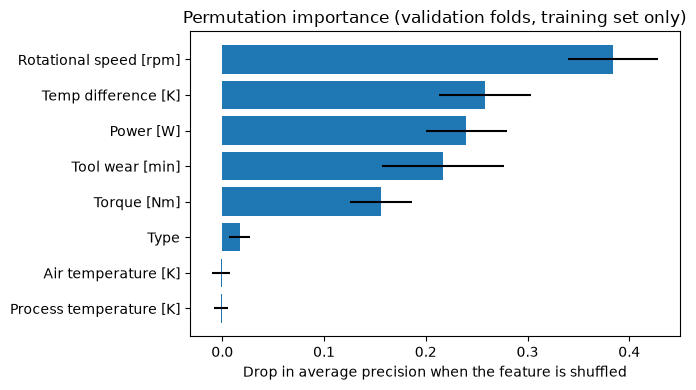

In [10]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(importance_table.index[::-1], importance_table["mean drop in average precision"][::-1],
        xerr=importance_table["std across folds"][::-1])
ax.set_xlabel("Drop in average precision when the feature is shuffled")
ax.set_title("Permutation importance (validation folds, training set only)")
plt.tight_layout()
plt.show()

**Findings:**
- Rotational speed matters most (average precision drops by 0.384 when it is shuffled), followed by temperature difference (0.258), power (0.240), tool wear (0.217) and torque (0.156).
- Air and process temperature score about 0 on their own. The model uses their difference instead, so shuffling one temperature alone barely matters. Type adds little (0.017).
- Features built from each other share their importance. Shuffling torque does not change the power column, so torque's own score understates how much the model uses it. These scores show what the model relies on, not what causes failures.